# TP4 - Procesamiento de arreglos 

## Imports

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal

# Pregunta 1

Primero de todo, estableciendo todos los constantes

In [9]:
ARCHIVO = "mtms-arrC1A.wav"
Fc = 2000.0          # frecuencia portadora [Hz]
c = 343.0            # velocidad del sonido [m/s]
T_BLOQUE = 0.1       # duración de cada bloque temporal [s]
NFFT_ESP = 256       # puntos de la FFT espacial (zero-padding)

## Escogiendo el sub-arreglo

En este escogemos el sub-arreglo que queremos utilizar. Primero de todo, para escoger el sub-arreglo tenemos que determinar la distancia maxima entre sensores para no tener aliasing espacial. A 2000 Hz, $\lambda = c/f \approx 17{,}2$ cm, así que $\lambda/2 \approx 8{,}6$ cm.

Entoncés podemos descartar el arreglo que tiene 16cm entre sensores, debido a que va a tener aliasing espectral. Después quedan dos para escoger el de 4cm y 8cm entre sensores, pero con el mismo numeros de sensores. Cuando ya cumplis con aliasing espectrla no hay mucho beneficio de reducir la distancia entre sensores, y además tenes información redundante entoncés 8cm ya es suficiente. Además como el numero de sensores entre los dos son igual, si reducis la distancia entre ellos vas a tener una distancia menor entre el primer y utilmo sensor y entonces tu apertura va a ser menor (para el caso de 4cm). Una apertura mas pequeña significa que podes caputrar menos energía.

Entoncés debido a estas razones escogimos el arreglo con 8cm entre sensores (abajo hay una tabla que resume todos los numeros).

| Criterio | 4 cm | 8 cm | 16 cm |
|---|---|---|---|
| Aliasing ($d < \lambda/2$) | No | No (justo) | **Sí** |
| Apertura | ~32 cm | ~64 cm | ~96 cm |
| Resolución angular | Peor | Buena | Mejor, pero ambigua |
| Sensores | 9 | 9 | 7 |

In [13]:
# Posiciones de los 15 micrófonos [m], con el elemento 0 como origen
pos = np.array([0.00, 0.16, 0.24, 0.32, 0.36, 0.40, 0.44, 0.48, 0.52,
                 0.56, 0.60, 0.64, 0.72, 0.80, 0.96])

# Sub-arreglos (índices de micrófonos)
subarreglos = {
    "4 cm":  [3, 4, 5, 6, 7, 8, 9, 10, 11],
    "8 cm":  [1, 2, 3, 5, 7, 9, 11, 12, 13],
    "16 cm": [0, 1, 3, 7, 11, 13, 14],
}

ELEGIDO = "8 cm"   
d = float(ELEGIDO[0]) / 100

Ahora que escogimos el sub arreglo podemos cargar todos los datos

In [14]:
SUB = subarreglos[ELEGIDO]

Fs, x = wavfile.read(ARCHIVO)
x = np.swapaxes(x.astype(float), 0, 1)
xs = np.take(x, SUB, axis=0)
N = xs.shape[1]
n = np.arange(N)

## Escogiendo el Ancho de Banda

A la hora de escoger el ancho de banda tenes un compromiso. Queres el B minimo para poder cumplir la condicion de banda angosta. Si tenes un B muy grande entoncés empieza a tener desfasajes tu señal, y asumir que todo tu desfasaje viene solo de la dirreción de entrada no es completamente cierto. Esto causa que la señal no sea tan nitidia.

En cambio, si tenes un B mas grande podes capturar mas energia y mas snapshots de la entrada, pero la condicion de banda angosta no se cumple tan bien. Mas snapshots de la entrada me refiero a la idea que tenes mas inforamción en una banda mas grande sobre la señal entoncés tenes mas infromación sobre la señal, que quizas podes utilizar después para promediar y eliminar el ruido. [encontrar una cita].

Entoncés la idea es comaprar varios valroes de B, ver si la señal de voz se puede recuperar y escoger el valor de B mas grande adonde la voz se puede seguir recuperando.

Primero de todo estableciendo los parametros que vamos a utilizar.

In [16]:
# estableciendo todos los parametros
B_LISTA = [25, 50, 100, 200, 400, 800, 1600] # B q se van a considerar
T_BLOQUE = 0.1
NFFT_ESP = 512
PERCENTIL_VOZ = 75     # bloques con potencia sobre este percentil = "hay voz"
lam = c / Fc

Ahora estableciendo varias funciones que vamos a utilizar para este analisis.

Primero de todo la función de demodular la señal, que simplemente demoluda la señal con las especificaciones que pide las instrucciones y un pasabajos butterworth. Escogimos un butterworth como nuestro filtro pasabajos porque es bastante plano y para este caso funciona. Además, aplicamos el filtro utilizando sosfiltfilt que es una funcion de python que asegura que el filtro no tenga ningun tipo de fase, y que todos los canales sean afectados de la misma manera. Esto es especilamente importante para el caso epscial, ya que queremos que el desfasaje sea solamente debido al angulo de arribo. 

También tenemos la funcoin de espectro_por_bloque que simplemenete genera el espectro de un bloque de entrada.

Y finalemnte tenemos el ancho_3db, que simplemente encuentra el ancho (en grados) de la región alrededor de un pico "k" adonde la potencia baje por 3db.

In [ ]:
def demodular(B):
    xd = xs * np.exp(-2j * np.pi * Fc / Fs * n)
    sos = signal.butter(6, (B / 2) / (Fs / 2), btype="low", output="sos")
    xd = signal.sosfiltfilt(sos, xd, axis=1)
    M = max(int(Fs // B), 1)
    return xd[:, ::M], Fs / M


def espectro_por_bloque(xd, Fs2):
    L = max(int(T_BLOQUE * Fs2), 1)
    nb = xd.shape[1] // L
    P = np.zeros((NFFT_ESP, nb))
    for b in range(nb):
        X = np.fft.ifft(xd[:, b * L:(b + 1) * L], n=NFFT_ESP, axis=0)
        P[:, b] = np.mean(np.abs(X) ** 2, axis=1)
    return np.fft.fftshift(P, axes=0), L


def ancho_3dB(p_dB, k):
    """Ancho (grados) de la región contigua alrededor del pico k con p >= pico-3dB."""
    umbral = p_dB[k] - 3
    i = k
    while i > 0 and p_dB[i - 1] >= umbral:
        i -= 1
    j = k
    while j < len(p_dB) - 1 and p_dB[j + 1] >= umbral:
        j += 1
    return theta[j] - theta[i]

Ahora que tenemos todos los variables definidos y ya creamos las funciones necesarias solo hace falta comaprar los resultados para todos los diferentes valores de B.

  B [Hz]  snapsh/bloque  ang pico  ancho -3dB  pico/piso dB
      25              2       1.4        15.9           7.7
      50              5       2.2        15.9           8.0
     100             10       1.9        15.2           8.1
     200             20       1.0        14.9           7.5
     400             40       1.0        14.9           7.3
     800             80       0.2        14.2           8.3
    1600            160       0.7        14.7           9.0


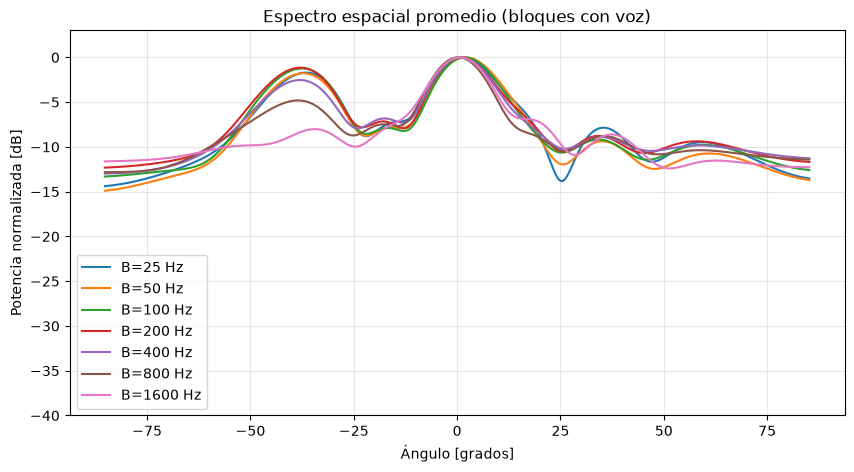

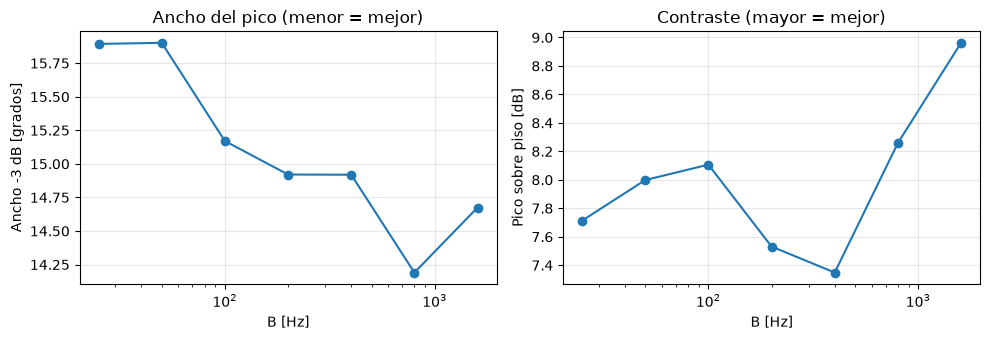

In [20]:
#transformado el desfasaje angular en el angulo espacial
psi = np.fft.fftshift(np.fft.fftfreq(NFFT_ESP)) * 2 * np.pi
u = psi * lam / (2 * np.pi * d)
vis = np.abs(u) <= 1
theta = np.degrees(np.arcsin(u[vis]))

#ahora comparando los resultados de todos los B
resultados = []
plt.figure(figsize=(10, 5))
for B in B_LISTA:
    xd, Fs2 = demodular(B)
    P, L = espectro_por_bloque(xd, Fs2)
    P = P[vis, :]

    pot_bloque = P.sum(axis=0)
    activos = pot_bloque >= np.percentile(pot_bloque, PERCENTIL_VOZ)
    Pm = P[:, activos].mean(axis=1)               # espectro promedio en bloques con voz
    Pm_dB = 10 * np.log10(Pm + 1e-12)

    k = np.argmax(Pm_dB)
    ancho = ancho_3dB(Pm_dB, k)
    pico_piso = Pm_dB[k] - np.median(Pm_dB)
    resultados.append((B, L, theta[k], ancho, pico_piso))
    plt.plot(theta, Pm_dB - Pm_dB[k], label=f"B={B} Hz")

plt.xlabel("Ángulo [grados]")
plt.ylabel("Potencia normalizada [dB]")
plt.title("Espectro espacial promedio (bloques con voz)")
plt.ylim(-40, 3)
plt.legend()
plt.grid(alpha=0.3)

print(f"{'B [Hz]':>8} {'snapsh/bloque':>14} {'ang pico':>9} {'ancho -3dB':>11} {'pico/piso dB':>13}")
for B, L, ang, w, pp in resultados:
    print(f"{B:8d} {L:14d} {ang:9.1f} {w:11.1f} {pp:13.1f}")

Bs = [r[0] for r in resultados]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].semilogx(Bs, [r[3] for r in resultados], "o-")
ax[0].set_xlabel("B [Hz]"); ax[0].set_ylabel("Ancho -3 dB [grados]")
ax[0].set_title("Ancho del pico (menor = mejor)"); ax[0].grid(alpha=0.3)
ax[1].semilogx(Bs, [r[4] for r in resultados], "o-")
ax[1].set_xlabel("B [Hz]"); ax[1].set_ylabel("Pico sobre piso [dB]")
ax[1].set_title("Contraste (mayor = mejor)"); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cargando todos los datos y demodulando la señal como indica las instruciones

In [5]:
Fs, x = wavfile.read(ARCHIVO)          # x: (N, 15)
x = x.astype(float)
x = np.swapaxes(x, 0, 1)               # ahora (15 canales, N muestras)
N = x.shape[1]
print(f"Fs = {Fs} Hz, canales = {x.shape[0]}, duración = {N/Fs:.1f} s")

# Sub-arreglo
idx = subarreglos[ELEGIDO]
xs = np.take(x, idx, axis=0)
d = np.mean(np.diff(pos[idx]))         # espaciamiento [m]
lam = c / Fc
print(f"Sub-arreglo {ELEGIDO}: d = {d*100:.1f} cm, lambda/2 = {lam/2*100:.2f} cm")

# ---------------------------------------------------------------
# Demodulación a banda base + pasa-bajos + diezmado
# ---------------------------------------------------------------
xd = xs * np.exp(-2j * np.pi * Fc / Fs * np.arange(N))   # baja Fc a 0 Hz

sos = signal.butter(6, (B / 2) / (Fs / 2), btype="low", output="sos")
xd = signal.sosfiltfilt(sos, xd, axis=1)

M = int(Fs // B)                       # factor de diezmado (Fs_nueva >= B)
xd = xd[:, ::M]
Fs2 = Fs / M
print(f"Diezmado x{M}: nueva Fs = {Fs2:.0f} Hz, muestras = {xd.shape[1]}")

Fs = 16000 Hz, canales = 15, duración = 34.0 s
Sub-arreglo 8 cm: d = 8.0 cm, lambda/2 = 8.58 cm
Diezmado x80: nueva Fs = 200 Hz, muestras = 6794


Graficiando el espectograma

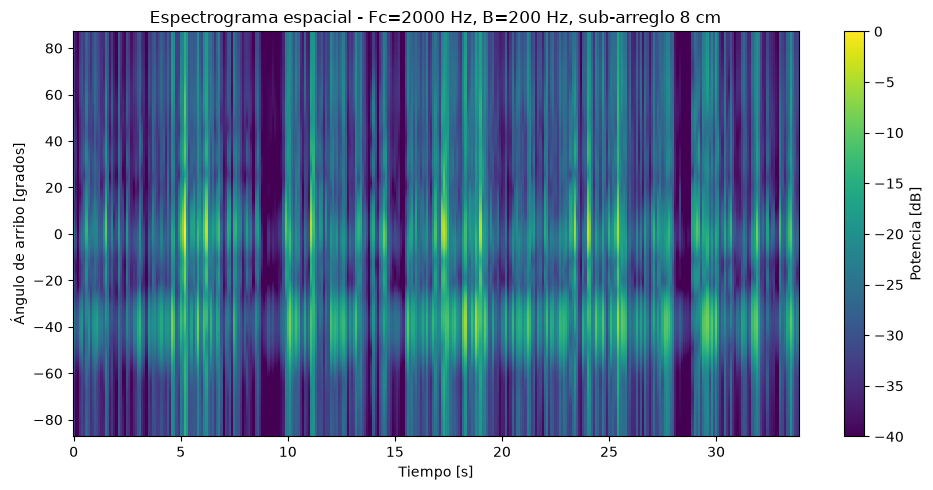

In [6]:
# ---------------------------------------------------------------
# Espectrograma de frecuencia espacial
# FFT a lo largo de los sensores, promediando |.|^2 sobre las muestras
# (snapshots) de cada bloque temporal.
# ---------------------------------------------------------------
K, T = xd.shape
L = int(T_BLOQUE * Fs2)                # snapshots por bloque
nb = T // L
P = np.zeros((NFFT_ESP, nb))
for b in range(nb):
    blk = xd[:, b * L:(b + 1) * L]                         # (K, L)
    X = np.fft.ifft(blk, n=NFFT_ESP, axis=0)               # FFT espacial
    P[:, b] = np.mean(np.abs(X) ** 2, axis=1)
P = np.fft.fftshift(P, axes=0)

# Eje espacial: psi = 2*pi*d*sin(theta)/lambda  ->  sin(theta) = psi*lambda/(2*pi*d)
psi = np.fft.fftshift(np.fft.fftfreq(NFFT_ESP)) * 2 * np.pi
u = psi * lam / (2 * np.pi * d)        # = sin(theta)
visible = np.abs(u) <= 1               # región física (|sin theta| <= 1)

P_dB = 10 * np.log10(P + 1e-12)
P_dB -= P_dB.max()

t = np.arange(nb) * T_BLOQUE
theta = np.degrees(np.arcsin(u[visible]))

# ---------------------------------------------------------------
# Gráfico
# ---------------------------------------------------------------
plt.figure(figsize=(10, 5))
plt.pcolormesh(t, theta, P_dB[visible, :], shading="auto", vmin=-40, vmax=0)
plt.colorbar(label="Potencia [dB]")
plt.xlabel("Tiempo [s]")
plt.ylabel("Ángulo de arribo [grados]")
plt.title(f"Espectrograma espacial - Fc={Fc:.0f} Hz, B={B:.0f} Hz, sub-arreglo {ELEGIDO}")
plt.tight_layout()
plt.show()